# Notebook 09: Knowledge-Based + Hybrid (v2)

**Goal:** build the fifth recommender (Knowledge-Based, cycle-phase rules), blend all systems into a **Hybrid** with weights, and produce the final comparison table for the presentation.

**Inputs:**
- `recipes_labeled.pkl` (notebook 05)
- `recipes_nutrients.pkl` (notebook 04, for the nutrient check)
- `interactions_train.pkl`, `recipe_stats_train.csv` (notebook 06)
- `catalog_ids.csv`, `eval_test_catalog.pkl`, `eval_users_sample.csv`, `tfidf_ingredients.npz`, `tfidf_recipe_ids.csv` (notebook 07)
- `results_07_08.csv` (notebook 08)

**What's new in v2 (11 Nov):**
- Personal weights can be **fixed** (`FIXED_WEIGHTS`). Default: Content ¼ + Item-CF ¼ + User-CF ½. In v1 the auto-pick chose Item ⅔ + User ⅓ by an NDCG difference of 0.0001 (a tie), which drops Content-Based, the only system that works for new recipes and the user's own recipes.
- Nutrient check now reads the nutrient columns from `recipes_nutrients.pkl`.
- Repeat cap 30%, phase target 4.5 of 10.
- Whole notebook in English.

**Agreed decisions (10 Nov):**
1. **Knowledge-Based:** rank the catalog by the phase score `score_<phase>`. Not personal. **Not judged by HitRate** (we don't know the phase of test users when they rated), but by sanity checks: nutrients, share of phase-labelled recipes, categories, overlap between phases.
2. **Hybrid:** each system's score becomes a **per-user rank between 0 and 1**, then
   > score = w1·Popularity + w2·Content-B + w3·Item-CF + w4·User-CF + w5·Phase
3. **Weights in two stages:**
   - w1–w4: grid of combinations; auto-pick = best NDCG with no recipe shown to more than `MAX_REPEAT_PCT` of users (or fixed weights).
   - w5: trade-off curve: how much HitRate drops vs how many phase-suitable recipes reach the top 10.
4. **Systems carried over from 07 and 08:** Content-Based B (max-similarity), Item-Based Jaccard k=10, User-Based Jaccard k=100.

**App-only (not measurable here):** pantry matching, the user's own recipes, meal type.

**Outputs:** `kb_checks.csv`, `hybrid_grid.csv`, `phase_tradeoff.csv` + `phase_tradeoff.png`, `hybrid_weights.csv` (default slider values for the app), `results_final.csv`.

## 0. Settings

In [1]:
import os
import html
import time
from itertools import product

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.stats import rankdata

pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

# ---- inputs (path strings) ----
RECIPES_PKL = "recipes_labeled.pkl"
NUTRIENTS_PKL = "recipes_nutrients.pkl"      # optional: only for the nutrient check
TRAIN_PKL = "interactions_train.pkl"
STATS_CSV = "recipe_stats_train.csv"
CATALOG_CSV = "catalog_ids.csv"
EVAL_TEST_PKL = "eval_test_catalog.pkl"
EVAL_USERS_CSV = "eval_users_sample.csv"
TFIDF_NPZ = "tfidf_ingredients.npz"
TFIDF_IDS_CSV = "tfidf_recipe_ids.csv"
RESULTS_PREV_CSV = "results_07_08.csv"

# ---- outputs (path strings) ----
KB_CHECKS_CSV = "kb_checks.csv"
GRID_CSV = "hybrid_grid.csv"
TRADEOFF_CSV = "phase_tradeoff.csv"
TRADEOFF_PNG = "phase_tradeoff.png"
WEIGHTS_CSV = "hybrid_weights.csv"
RESULTS_FINAL_CSV = "results_final.csv"

# ---- decisions ----
K = 10
ITEM_K = 10                 # Item-Based Jaccard (from notebook 08)
USER_K = 100                # User-Based Jaccard (from notebook 08)
WEIGHT_VALUES = [0, 1, 2]   # values tried for each personal weight (w1..w4)
MAX_REPEAT_PCT = 30         # no recipe shown to more than this % of users
FIXED_WEIGHTS = (0, 0.25, 0.25, 0.5)   # (Popularity, Content-B, Item-CF, User-CF); None = auto-pick from the grid
PHASE_WEIGHTS = [0, 0.1, 0.25, 0.3, 0.35, 0.4, 0.5, 0.75, 1, 1.5, 2]   # w5 values (personal weights sum to 1)
TARGET_PHASE_IN_TOP10 = 4.5 # target: phase-suitable recipes in the top 10
TOP_N_CHECK = 50            # how many recipes the Knowledge-Based checks look at
BATCH = 250
CHUNK = 500

for p in [RECIPES_PKL, TRAIN_PKL, STATS_CSV, CATALOG_CSV, EVAL_TEST_PKL, EVAL_USERS_CSV,
          TFIDF_NPZ, TFIDF_IDS_CSV, RESULTS_PREV_CSV]:
    assert isinstance(p, str), f"{p!r} must be a path string"
    assert os.path.exists(p), f"{p} not found: run notebooks 07 and 08 first, or fix the path"

## 1. Load data

In [2]:
recipes = pd.read_pickle(RECIPES_PKL).reset_index(drop=True)
recipes["RecipeId"] = recipes["RecipeId"].astype("int64")
recipes["Name"] = recipes["Name"].astype(str).map(html.unescape)
rec_by_id = recipes.set_index("RecipeId")

train = pd.read_pickle(TRAIN_PKL)
train["user_id"] = train["user_id"].astype("int64")
train["recipe_id"] = train["recipe_id"].astype("int64")
stats = pd.read_csv(STATS_CSV)
stats["recipe_id"] = stats["recipe_id"].astype("int64")

catalog_ids = pd.read_csv(CATALOG_CSV)["recipe_id"].astype("int64").to_numpy()
test_cat = pd.read_pickle(EVAL_TEST_PKL)
eval_users = pd.read_csv(EVAL_USERS_CSV)["user_id"].astype("int64").to_numpy()
results_prev = pd.read_csv(RESULTS_PREV_CSV)

X = sparse.load_npz(TFIDF_NPZ).tocsr()
tfidf_ids = pd.read_csv(TFIDF_IDS_CSV)["recipe_id"].astype("int64").to_numpy()
assert (tfidf_ids == recipes["RecipeId"].to_numpy()).all(), "TF-IDF row order does not match recipes_labeled.pkl: re-run notebook 07"

n_cat = len(catalog_ids)
cat_set = set(catalog_ids)
cat_index = pd.Series(np.arange(n_cat), index=catalog_ids)
n_eval = len(eval_users)
u_pos = pd.Series(np.arange(n_eval), index=eval_users)
sample_label = "all" if n_eval == test_cat["user_id"].nunique() else f"sample {n_eval}"

# phase columns: score_<phase> and label_<phase>
phases = [c[len("score_"):] for c in recipes.columns if c.startswith("score_") and f"label_{c[len('score_'):]}" in recipes.columns]
assert phases, "no score_* / label_* columns in recipes_labeled.pkl"
print("phases:", phases)
print(f"recipes: {len(recipes):,} | catalog: {n_cat:,} | eval users: {n_eval:,} ({sample_label})")

phases: ['menstrual', 'follicular', 'ovulatory', 'luteal']
recipes: 42,736 | catalog: 12,375 | eval users: 2,392 (all)


## 2. Evaluation framework (same as 07 and 08) + repeat column

`max_repeat_%` = the highest share of users who got the same recipe. A direct measure of the repetition concern.

In [3]:
tc = test_cat[test_cat["user_id"].isin(u_pos.index)]
relevant = (tc.assign(ci=cat_index.loc[tc["recipe_id"]].to_numpy())
              .groupby("user_id")["ci"].apply(np.array).to_dict())
tr = train[train["user_id"].isin(u_pos.index) & train["recipe_id"].isin(cat_set)]
seen = (tr.assign(ci=cat_index.loc[tr["recipe_id"]].to_numpy())
          .groupby("user_id")["ci"].apply(np.array).to_dict())

_disc = 1.0 / np.log2(np.arange(2, K + 2))
_train_ids = set(train["recipe_id"])
cold_ci = cat_index.loc[[r for r in catalog_ids if r not in _train_ids]].to_numpy()


def mask_seen(S, rows):
    for r_, row in enumerate(rows):
        s_ = seen.get(eval_users[row])
        if s_ is not None:
            S[r_, s_] = -np.inf
    return S


def topk(S):
    top = np.argpartition(-S, K, axis=1)[:, :K]
    order_ = np.argsort(-np.take_along_axis(S, top, axis=1), axis=1)
    return np.take_along_axis(top, order_, axis=1)


def recommend(score_fn):
    out = np.empty((n_eval, K), dtype=np.int64)
    for start in range(0, n_eval, BATCH):
        rows = np.arange(start, min(start + BATCH, n_eval))
        S = mask_seen(np.array(score_fn(rows), dtype=np.float32, copy=True), rows)
        out[rows] = topk(S)
    return out


def evaluate(recs, name):
    hits = np.zeros(n_eval, dtype=bool)
    ndcg = np.zeros(n_eval)
    cold_hit_count = 0
    for row, u in enumerate(eval_users):
        rel = relevant[u]
        h = np.isin(recs[row], rel)
        hits[row] = h.any()
        cold_hit_count += int(np.isin(recs[row][h], cold_ci).sum())
        ndcg[row] = (h * _disc).sum() / _disc[:min(len(rel), K)].sum()
    _, cnt = np.unique(recs, return_counts=True)
    return {"system": name,
            f"HitRate@{K}": round(float(hits.mean()), 4),
            f"NDCG@{K}": round(float(ndcg.mean()), 4),
            "Coverage_%": round(len(cnt) / n_cat * 100, 2),
            "max_repeat_%": round(cnt.max() / n_eval * 100, 1),
            "hit_users": int(hits.sum()),
            "cold_hits": cold_hit_count,
            "eval_users": sample_label}


def most_repeated(recs, n=5):
    ids, cnt = np.unique(recs, return_counts=True)
    top = np.argsort(-cnt)[:n]
    rid = catalog_ids[ids[top]]
    return pd.DataFrame({"Name": rec_by_id.loc[rid, "Name"].to_numpy(),
                         "Category": rec_by_id.loc[rid, "RecipeCategory"].to_numpy(),
                         "users_%": (cnt[top] / n_eval * 100).round(1)})


def rank01(M):
    """Per-row relative rank: highest = 1, lowest = 0, ties share the same value."""
    M = np.atleast_2d(M)
    r = rankdata(M, axis=1, method="average")
    return ((r - 1) / (M.shape[1] - 1)).astype(np.float32)

## 3. Knowledge-Based: ranking by cycle phase

For each phase the catalog is sorted by `score_<phase>`. Every user in that phase gets the same list.

In [4]:
phase_score = {p: rec_by_id.loc[catalog_ids, f"score_{p}"].fillna(0).to_numpy(np.float32) for p in phases}
phase_label = {p: rec_by_id.loc[catalog_ids, f"label_{p}"].fillna(False).astype(bool).to_numpy() for p in phases}
phase_rank = {p: rank01(phase_score[p])[0] for p in phases}

for p in phases:
    print(f"{p}: phase-labelled recipes in catalog = {phase_label[p].sum():,} ({phase_label[p].mean()*100:.1f}%)")

kb_top = {p: np.argsort(-phase_score[p])[:TOP_N_CHECK] for p in phases}
for p in phases:
    ids = catalog_ids[kb_top[p][:10]]
    print(f"\n=== {p}: top 10 ===")
    print(rec_by_id.loc[ids, ["Name", "RecipeCategory", f"score_{p}", f"label_{p}"]].to_string())

menstrual: phase-labelled recipes in catalog = 1,952 (15.8%)
follicular: phase-labelled recipes in catalog = 1,866 (15.1%)
ovulatory: phase-labelled recipes in catalog = 1,866 (15.1%)
luteal: phase-labelled recipes in catalog = 1,529 (12.4%)

=== menstrual: top 10 ===
                                                     Name   RecipeCategory  score_menstrual  label_menstrual
RecipeId                                                                                                    
115445                  Spirit's Spinach Stuffed Tomatoes        Vegetable         0.976665             True
236851                        Chicken , Leeks and Spinach          Poultry         0.925550             True
430060                                 Ange's Pizza Sauce  Low Cholesterol         0.895577             True
375232    Grilled Mozzarella and Sun-Dried Tomato Skewers           Cheese         0.888500             True
222342                              Wildberry Summer Soup          Dessert   

### Sanity checks

1. **Nutrients:** median nutrient density (per 100 kcal) in the top 50 ÷ the catalog median. Above 1 = the list is richer in that nutrient.
2. **Labelled share:** how many of the top 50 carry `label_<phase>`.
3. **Sweets & baked goods:** share of sweet/baked categories in the top 50 vs the catalog.
4. **Overlap between phases:** share of recipes shared by the top 50 of each pair of phases.

In [5]:
NUTR_SHOW = ["iron_mg", "magnesium_mg", "vitc_mg", "folate_ug", "vitb6_mg", "calcium_mg", "potassium_mg",
             "zinc_mg", "fiber_g", "protein_g"]
dens = None
if os.path.exists(NUTRIENTS_PKL):
    nut = pd.read_pickle(NUTRIENTS_PKL)
    nut["RecipeId"] = nut["RecipeId"].astype("int64")
    nut = nut.drop_duplicates("RecipeId").set_index("RecipeId")
    cols = [f"{n}_ps" for n in NUTR_SHOW if f"{n}_ps" in nut.columns]
    if "kcal_ps" in nut.columns and cols:
        kcal = nut["kcal_ps"].where(nut["kcal_ps"] > 0)
        dens = nut[cols].div(kcal, axis=0) * 100          # per 100 kcal
        dens.columns = [c.replace("_ps", "") for c in cols]
        print(f"nutrient density columns: {list(dens.columns)}")
    else:
        print("⚠ kcal_ps or nutrient *_ps columns missing in", NUTRIENTS_PKL)
else:
    print(f"⚠ {NUTRIENTS_PKL} not found: nutrient check skipped")

SWEET = ["Dessert", "Breads", "Quick Breads", "Bar Cookie", "Drop Cookies", "Pie", "Cheesecake",
         "Candy", "Yeast Breads", "Scones", "Frozen Desserts", "Tarts", "Gelatin", "Beverages", "Smoothies"]
cats_cat = rec_by_id.loc[catalog_ids, "RecipeCategory"]

rows_ = {}
for p in phases:
    sel = catalog_ids[kb_top[p]]
    r_ = {}
    if dens is not None:
        cat_med = dens.reindex(catalog_ids).median()
        top_med = dens.reindex(sel).median()
        for c in dens.columns:
            r_[f"{c}_x_catalog"] = round(float(top_med[c] / cat_med[c]), 2) if cat_med[c] > 0 else np.nan
    r_["labelled_%_top50"] = round(phase_label[p][kb_top[p]].mean() * 100, 1)
    r_["sweet_%_top50"] = round(rec_by_id.loc[sel, "RecipeCategory"].isin(SWEET).mean() * 100, 1)
    rows_[p] = r_
rows_["catalog"] = {"sweet_%_top50": round(cats_cat.isin(SWEET).mean() * 100, 1)}
kb_checks = pd.DataFrame(rows_).T
print(f"Top {TOP_N_CHECK} per phase vs catalog (nutrient columns = median density ratio, per 100 kcal):")
kb_checks

nutrient density columns: ['iron_mg', 'magnesium_mg', 'vitc_mg', 'folate_ug', 'vitb6_mg', 'calcium_mg', 'potassium_mg', 'zinc_mg', 'fiber_g', 'protein_g']
Top 50 per phase vs catalog (nutrient columns = median density ratio, per 100 kcal):


,iron_mg_x_catalog,magnesium_mg_x_catalog,vitc_mg_x_catalog,folate_ug_x_catalog,vitb6_mg_x_catalog,calcium_mg_x_catalog,potassium_mg_x_catalog,zinc_mg_x_catalog,fiber_g_x_catalog,protein_g_x_catalog,labelled_%_top50,sweet_%_top50
menstrual,5.64,5.31,28.63,2.64,4.57,3.83,8.45,2.47,6.48,1.57,100.0,12.0
follicular,1.54,2.77,6.87,1.33,3.47,9.04,3.00,5.04,2.87,4.68,100.0,6.0
ovulatory,1.54,2.77,6.87,1.33,3.47,9.04,3.00,5.04,2.87,4.68,100.0,6.0
luteal,3.14,5.33,21.51,2.85,6.58,4.87,8.11,3.04,7.45,1.94,100.0,18.0
catalog,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.1


In [6]:
overlap = pd.DataFrame(index=phases, columns=phases, dtype=float)
for a in phases:
    for b in phases:
        overlap.loc[a, b] = round(len(set(kb_top[a]) & set(kb_top[b])) / TOP_N_CHECK * 100, 1)
print(f"Overlap between the top {TOP_N_CHECK} of each pair of phases (%). Follicular = ovulatory is expected (same rules):")
overlap

Overlap between the top 50 of each pair of phases (%). Follicular = ovulatory is expected (same rules):


,menstrual,follicular,ovulatory,luteal
menstrual,100.0,10.0,10.0,36.0
follicular,10.0,100.0,100.0,26.0
ovulatory,10.0,100.0,100.0,26.0
luteal,36.0,26.0,26.0,100.0


In [7]:
# For information only (not a fair test): HitRate per phase if every user were in that phase
kb_results = [evaluate(recommend(lambda rows, p=p: np.broadcast_to(phase_score[p], (len(rows), n_cat))),
                       f"Knowledge-Based ({p}) [for info]") for p in phases]
pd.DataFrame(kb_results).set_index("system")

,HitRate@10,NDCG@10,Coverage_%,max_repeat_%,hit_users,cold_hits,eval_users
system,,,,,,,
Knowledge-Based (menstrual) [for info],0.0013,0.0003,0.09,100.0,3,1,all
Knowledge-Based (follicular) [for info],0.0017,0.0004,0.10,100.0,4,0,all
Knowledge-Based (ovulatory) [for info],0.0017,0.0004,0.10,100.0,4,0,all
Knowledge-Based (luteal) [for info],0.0021,0.0005,0.09,100.0,5,1,all


## 4. Hybrid components

The four personal systems, built exactly as in 07 and 08, each turned into a per-user rank (0 to 1).

In [8]:
# Popularity
st = stats.set_index("recipe_id").reindex(catalog_ids)
wr = st["weighted_rating"].fillna(-1).to_numpy()
ni = st["n_interactions"].fillna(0).to_numpy()
pop_order = np.lexsort((ni, wr))
pop_score = np.empty(n_cat, dtype=np.float32)
pop_score[pop_order] = np.arange(n_cat)
pop_rank = rank01(pop_score)[0]

# matrices (same as notebook 08)
all_rids = recipes["RecipeId"].to_numpy()
rid_to_col = pd.Series(np.arange(len(all_rids)), index=all_rids)
n_items = len(all_rids)
tr_all = train[train["recipe_id"].isin(rid_to_col.index)].copy()
train_users = np.sort(tr_all["user_id"].unique())
uid_to_row = pd.Series(np.arange(len(train_users)), index=train_users)
n_users = len(train_users)
tr_all["r"] = uid_to_row.loc[tr_all["user_id"]].to_numpy()
tr_all["c"] = rid_to_col.loc[tr_all["recipe_id"]].to_numpy()


def mat(df_, vals):
    return sparse.csr_matrix((vals, (df_["r"].to_numpy(), df_["c"].to_numpy())), shape=(n_users, n_items), dtype=np.float32)


B = mat(tr_all, np.ones(len(tr_all)))
lk = tr_all[tr_all["liked"]]
L_all = mat(lk, np.ones(len(lk)))
eval_rows_in_train = uid_to_row.loc[eval_users].to_numpy()
L_eval = L_all[eval_rows_in_train]
cat_cols = rid_to_col.loc[catalog_ids].to_numpy()
print(f"B: {n_users:,} × {n_items:,} | nnz {B.nnz:,}")

B: 60,183 × 42,736 | nnz 146,775


In [9]:
# Content-Based B (max-similarity)
X_cat_T = X[cat_cols].T.tocsc()


def content_max(rows):
    S = np.zeros((len(rows), n_cat), dtype=np.float32)
    for r_, row in enumerate(rows):
        liked_rows = L_eval[row].indices
        if len(liked_rows):
            S[r_] = (X[liked_rows] @ X_cat_T).max(axis=0).toarray().ravel()
    return S


# Item-Based Jaccard (k = ITEM_K)
def item_jaccard_knn(M, k):
    Mt = M.T.tocsr()
    cnt = np.asarray(M.sum(axis=0)).ravel()
    rows_l, cols_l, vals_l = [], [], []
    for s in range(0, n_cat, CHUNK):
        cols = cat_cols[s:s + CHUNK]
        co = (Mt @ M[:, cols]).toarray()
        denom = cnt[:, None] + cnt[cols][None, :] - co
        sim = np.divide(co, denom, out=np.zeros_like(co), where=denom > 0)
        sim[cols, np.arange(len(cols))] = 0
        top = np.argpartition(-sim, k, axis=0)[:k]
        tv = np.take_along_axis(sim, top, axis=0)
        rows_l.append(top.T.ravel()); vals_l.append(tv.T.ravel())
        cols_l.append(np.repeat(np.arange(s, s + len(cols)), k))
    r_, c_, v_ = np.concatenate(rows_l), np.concatenate(cols_l), np.concatenate(vals_l)
    keep = v_ > 0
    return sparse.csr_matrix((v_[keep], (r_[keep], c_[keep])), shape=(n_items, n_cat))


t0 = time.time()
S_item = item_jaccard_knn(B, ITEM_K)
print(f"Item-Based Jaccard k={ITEM_K}: {time.time() - t0:.0f}s")


def item_cf(rows):
    return (L_eval[rows] @ S_item).toarray()


# User-Based Jaccard (k = USER_K)
B_cnt = np.asarray(B.sum(axis=1)).ravel()
B_T = B.T.tocsr()
L_cat = L_all[:, cat_cols].tocsr()


def user_cf(rows):
    co = (L_eval[rows] @ B_T).toarray()
    p_cnt = np.asarray(L_eval[rows].sum(axis=1)).ravel()
    denom = p_cnt[:, None] + B_cnt[None, :] - co
    sim = np.divide(co, denom, out=np.zeros_like(co), where=denom > 0)
    sim[np.arange(len(rows)), eval_rows_in_train[rows]] = 0
    top = np.argpartition(-sim, USER_K, axis=1)[:, :USER_K]
    W = np.zeros_like(sim)
    np.put_along_axis(W, top, np.take_along_axis(sim, top, axis=1), axis=1)
    return np.asarray((sparse.csr_matrix(W) @ L_cat).todense())


def components(rows):
    """Per-user ranks of each system: [Popularity, Content, Item-CF, User-CF], each (rows × n_cat)."""
    return [np.broadcast_to(pop_rank, (len(rows), n_cat)),
            rank01(content_max(rows)), rank01(item_cf(rows)), rank01(user_cf(rows))]

Item-Based Jaccard k=10: 4s


## 5. Stage 1: personal weights (w1–w4)

Components are computed once per batch of users, and **every** weight combination is scored on them. Duplicate combinations (e.g. 1,1,1,1 and 2,2,2,2) are dropped because they give the same ranking.

**Check:** each system alone (weight 1, others 0) should match notebooks 07/08 very closely (small differences come from ties).

In [10]:
names = ["Popularity", "Content-B", "Item-CF", "User-CF"]
combos = set()
for w in product(WEIGHT_VALUES, repeat=4):
    if sum(w) == 0:
        continue
    combos.add(tuple(np.round(np.array(w) / sum(w), 4)))
if FIXED_WEIGHTS is not None:
    combos.add(tuple(np.round(np.array(FIXED_WEIGHTS, float) / sum(FIXED_WEIGHTS), 4)))
combos = sorted(combos)
print(f"combinations: {len(combos)}")

grid_recs = {w: np.empty((n_eval, K), dtype=np.int64) for w in combos}
t0 = time.time()
for start in range(0, n_eval, BATCH):
    rows = np.arange(start, min(start + BATCH, n_eval))
    comps = components(rows)
    for w in combos:
        S = sum(wi * ci for wi, ci in zip(w, comps) if wi > 0).astype(np.float32)
        grid_recs[w][rows] = topk(mask_seen(np.array(S, copy=True), rows))
    print(f"  users {rows[-1] + 1:,}/{n_eval:,} | {time.time() - t0:.0f}s")

grid = pd.DataFrame([{**dict(zip(names, w)), **evaluate(grid_recs[w], str(w))} for w in combos]).drop(columns="system")
grid = grid.sort_values(f"NDCG@{K}", ascending=False).reset_index(drop=True)

singles = grid[(grid[names] == 1).any(axis=1)]
print("\nCheck: each system alone")
print(singles[names + [f"HitRate@{K}", "hit_users", "Coverage_%", "max_repeat_%"]].to_string(index=False))

combinations: 65
  users 250/2,392 | 3s
  users 500/2,392 | 6s
  users 750/2,392 | 8s
  users 1,000/2,392 | 11s
  users 1,250/2,392 | 14s
  users 1,500/2,392 | 16s
  users 1,750/2,392 | 19s
  users 2,000/2,392 | 21s
  users 2,250/2,392 | 24s
  users 2,392/2,392 | 25s

Check: each system alone
 Popularity  Content-B  Item-CF  User-CF  HitRate@10  hit_users  Coverage_%  max_repeat_%
        0.0        0.0      0.0      1.0      0.0895        214       17.04          40.8
        0.0        0.0      1.0      0.0      0.0468        112       28.27          13.7
        1.0        0.0      0.0      0.0      0.0134         32        0.11          99.8
        0.0        1.0      0.0      0.0      0.0063         15       32.93           7.6


In [11]:
print(f"Top 15 combinations by NDCG (of {len(grid)}):")
grid.head(15)

Top 15 combinations by NDCG (of 65):


,Popularity,Content-B,Item-CF,User-CF,HitRate@10,NDCG@10,Coverage_%,max_repeat_%,hit_users,cold_hits,eval_users
0,0.0000,0.0000,0.3333,0.6667,0.0991,0.0374,25.71,35.1,237,0,all
1,0.0000,0.0000,0.5000,0.5000,0.0920,0.0347,25.71,31.9,220,0,all
2,0.0000,0.0000,0.0000,1.0000,0.0895,0.0341,17.04,40.8,214,0,all
3,0.2857,0.1429,0.2857,0.2857,0.0903,0.0341,16.48,37.0,216,0,all
4,0.2000,0.2000,0.2000,0.4000,0.0899,0.0340,18.10,37.6,215,0,all
5,0.1667,0.1667,0.3333,0.3333,0.0890,0.0335,19.27,35.6,213,0,all
6,0.3333,0.1667,0.1667,0.3333,0.0865,0.0334,13.33,39.1,207,0,all
7,0.0000,0.0000,0.6667,0.3333,0.0849,0.0325,25.86,26.5,203,0,all
8,0.4000,0.2000,0.2000,0.2000,0.0844,0.0325,11.12,38.7,202,0,all
9,0.0000,0.2500,0.2500,0.5000,0.0907,0.0324,25.43,29.6,217,0,all


In [12]:
show_cols = [f"HitRate@{K}", f"NDCG@{K}", "Coverage_%", "max_repeat_%", "hit_users"]
ok = grid[grid["max_repeat_%"] <= MAX_REPEAT_PCT]
if len(ok) == 0:
    print(f"⚠ no combination meets max_repeat ≤ {MAX_REPEAT_PCT}%: taking the best NDCG")
    ok = grid
auto = ok.iloc[0]
print(f"Auto-pick (best NDCG with max_repeat ≤ {MAX_REPEAT_PCT}%): {dict(zip(names, auto[names]))}")
print(auto[show_cols].to_string())

if FIXED_WEIGHTS is not None:
    w_best = tuple(np.round(np.array(FIXED_WEIGHTS, float) / sum(FIXED_WEIGHTS), 4))
    fixed_row = grid[(grid[names].round(4) == np.array(w_best)).all(axis=1)].iloc[0]
    print(f"\nFIXED weights used: {dict(zip(names, w_best))}")
    print(fixed_row[show_cols].to_string())
else:
    w_best = tuple(np.round(auto[names].to_numpy(float), 4))
    print("\nUsing the auto-pick.")

top_ndcg = grid.iloc[0]
print(f"\nFor comparison, best NDCG with no repeat cap: {dict(zip(names, top_ndcg[names]))}")
print(top_ndcg[show_cols].to_string())

recs_hybrid = grid_recs[w_best]
print("\nTop 5 most repeated recipes in the chosen Hybrid:")
print(most_repeated(recs_hybrid).to_string(index=False))

Auto-pick (best NDCG with max_repeat ≤ 30%): {'Popularity': np.float64(0.0), 'Content-B': np.float64(0.0), 'Item-CF': np.float64(0.6667), 'User-CF': np.float64(0.3333)}
HitRate@10      0.0849
NDCG@10         0.0325
Coverage_%       25.86
max_repeat_%      26.5
hit_users          203

FIXED weights used: {'Popularity': np.float64(0.0), 'Content-B': np.float64(0.25), 'Item-CF': np.float64(0.25), 'User-CF': np.float64(0.5)}
HitRate@10      0.0907
NDCG@10         0.0324
Coverage_%       25.43
max_repeat_%      29.6
hit_users          217

For comparison, best NDCG with no repeat cap: {'Popularity': np.float64(0.0), 'Content-B': np.float64(0.0), 'Item-CF': np.float64(0.3333), 'User-CF': np.float64(0.6667)}
HitRate@10      0.0991
NDCG@10         0.0374
Coverage_%       25.71
max_repeat_%      35.1
hit_users          237

Top 5 most repeated recipes in the chosen Hybrid:
                      Name     Category  users_%
    Oatmeal Raisin Cookies Drop Cookies     29.6
         Best Banana Brea

## 6. Stage 2: phase weight (w5)

Personal weights stay fixed (from stage 1, summing to 1); we add w5 × the phase rank.

For each w5 and each phase (as if every user were in that phase):
- **HitRate@10**: how well the system still finds what the user likes
- **phase_in_top10**: average number of **phase-labelled** recipes in the top 10

Pick = the smallest w5 that reaches `TARGET_PHASE_IN_TOP10` **and** keeps repetition ≤ `MAX_REPEAT_PCT`. Note: the phase score is the same for everyone, so a larger w5 increases repetition.

In [13]:
w_p = np.array(w_best, dtype=np.float32)
trade_recs = {(p, w5): np.empty((n_eval, K), dtype=np.int64) for p in phases for w5 in PHASE_WEIGHTS}
t0 = time.time()
for start in range(0, n_eval, BATCH):
    rows = np.arange(start, min(start + BATCH, n_eval))
    comps = components(rows)
    base = sum(wi * ci for wi, ci in zip(w_p, comps) if wi > 0).astype(np.float32)
    for p in phases:
        for w5 in PHASE_WEIGHTS:
            S = base + np.float32(w5) * phase_rank[p][None, :]
            trade_recs[(p, w5)][rows] = topk(mask_seen(np.array(S, copy=True), rows))
    print(f"  users {rows[-1] + 1:,}/{n_eval:,} | {time.time() - t0:.0f}s")

trade_rows = []
for (p, w5), rc in trade_recs.items():
    e = evaluate(rc, f"{p}, w5={w5}")
    e.update({"phase": p, "w5": w5, "phase_in_top10": round(float(phase_label[p][rc].sum(axis=1).mean()), 2)})
    trade_rows.append(e)
trade = pd.DataFrame(trade_rows)
trade_avg = (trade.groupby("w5")[[f"HitRate@{K}", f"NDCG@{K}", "Coverage_%", "max_repeat_%", "phase_in_top10"]]
                  .mean().round(4))
print("Average over phases:")
trade_avg

  users 250/2,392 | 2s
  users 500/2,392 | 4s
  users 750/2,392 | 5s
  users 1,000/2,392 | 7s
  users 1,250/2,392 | 9s
  users 1,500/2,392 | 10s
  users 1,750/2,392 | 12s
  users 2,000/2,392 | 14s
  users 2,250/2,392 | 15s
  users 2,392/2,392 | 16s
Average over phases:


,HitRate@10,NDCG@10,Coverage_%,max_repeat_%,phase_in_top10
w5,,,,,
0.00,0.0907,0.0324,25.4300,29.600,0.5275
0.10,0.0900,0.0312,25.2900,30.775,1.6050
0.25,0.0749,0.0265,23.0250,29.700,3.6975
0.30,0.0726,0.0249,21.9275,28.375,4.3725
0.35,0.0687,0.0233,20.7225,26.675,4.9675
0.40,0.0640,0.0213,19.5500,24.875,5.5400
0.50,0.0512,0.0166,17.5450,22.525,6.5200
0.75,0.0355,0.0101,14.0425,22.925,8.1450
1.00,0.0264,0.0069,11.7225,23.975,8.9975


chosen w5: 0.35 | phase_in_top10: 4.9675 | HitRate: 0.0907 → 0.0687 (-24%)


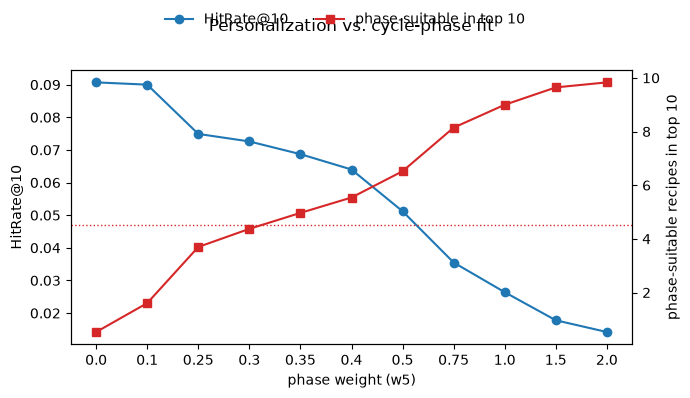

In [14]:
reach = trade_avg[trade_avg["phase_in_top10"] >= TARGET_PHASE_IN_TOP10]
reach_ok = reach[reach["max_repeat_%"] <= MAX_REPEAT_PCT]
if len(reach_ok):
    w5_best = float(reach_ok.index[0])
elif len(reach):
    w5_best = float(reach.index[0])
    print(f"⚠ no w5 reaches the target with repetition ≤ {MAX_REPEAT_PCT}%: taking the smallest that reaches the target")
else:
    w5_best = float(trade_avg.index[-1])
    print(f"⚠ no w5 reaches {TARGET_PHASE_IN_TOP10}: taking the largest")
h0 = trade_avg.loc[0, f"HitRate@{K}"]
h1 = trade_avg.loc[w5_best, f"HitRate@{K}"]
print(f"chosen w5: {w5_best} | phase_in_top10: {trade_avg.loc[w5_best, 'phase_in_top10']} "
      f"| HitRate: {h0:.4f} → {h1:.4f} ({(h1 / h0 - 1) * 100:+.0f}%)")

try:
    import matplotlib.pyplot as plt
    fig, ax1 = plt.subplots(figsize=(7, 4))
    ax1.plot(trade_avg.index.astype(str), trade_avg[f"HitRate@{K}"], marker="o", label=f"HitRate@{K}")
    ax1.set_xlabel("phase weight (w5)")
    ax1.set_ylabel(f"HitRate@{K}")
    ax2 = ax1.twinx()
    ax2.plot(trade_avg.index.astype(str), trade_avg["phase_in_top10"], marker="s", color="tab:red", label="phase-suitable in top 10")
    ax2.set_ylabel("phase-suitable recipes in top 10")
    ax2.axhline(TARGET_PHASE_IN_TOP10, color="tab:red", linestyle=":", linewidth=1)
    fig.legend(loc="upper center", ncol=2, frameon=False)
    ax1.set_title("Personalization vs. cycle-phase fit", pad=28)
    fig.tight_layout()
    fig.savefig(TRADEOFF_PNG, dpi=200)
    plt.show()
except ImportError:
    print("matplotlib not installed: %pip install matplotlib (the plot is optional; the table above has the same numbers)")

### Example user: Hybrid without and with phase

In [15]:
n_liked_eval = np.asarray(L_eval.sum(axis=1)).ravel()
ex_row = int(np.argmax(np.where(n_liked_eval <= 15, n_liked_eval, 0)))
ex_user = eval_users[ex_row]
ex_phase = phases[0]
liked_ex = lk.loc[lk["user_id"] == ex_user, "recipe_id"]
print(f"user {ex_user}: {len(liked_ex)} liked recipes in training")
print(rec_by_id.loc[liked_ex, ["Name", "RecipeCategory"]].head(10).to_string())

for w5 in [0, w5_best]:
    ids = catalog_ids[trade_recs[(ex_phase, w5)][ex_row]]
    print(f"\nHybrid ({ex_phase}, w5={w5}):")
    print(pd.DataFrame({"Name": rec_by_id.loc[ids, "Name"].to_numpy(),
                        "Category": rec_by_id.loc[ids, "RecipeCategory"].to_numpy(),
                        f"label_{ex_phase}": rec_by_id.loc[ids, f"label_{ex_phase}"].to_numpy(),
                        "hidden_hit": np.isin(trade_recs[(ex_phase, w5)][ex_row], relevant[ex_user])}).to_string())

user 12882: 15 liked recipes in training
                                                       Name   RecipeCategory
RecipeId                                                                    
3094                           Confectioner's Sugar Cookies          Dessert
8953                                Cream Cheese Pound Cake          Dessert
9973                       Pineapple and Sour Cream Muffins     Quick Breads
12736                                 Orange Glazed Chicken          Chicken
14059                           Lennie's Special Shortbread          Dessert
14467                                         Pecan Tassies              Pie
19542                                  Blue Cheese Dressing  Salad Dressings
21812                                   Peanut Butter Balls            Candy
24521                                         Blueberry Pie              Pie
26306     Copycat  Green Giant Niblets Corn in Butter Sauce             Corn

Hybrid (menstrual, w5=0):
        

## 7. Final comparison table

In [16]:
wlabel = " + ".join(f"{n} {w:g}" for n, w in zip(names, w_best) if w > 0)
hyb_personal = evaluate(recs_hybrid, f"Hybrid ({wlabel}), no phase")
hyb_phase = trade[trade["w5"] == w5_best][[f"HitRate@{K}", f"NDCG@{K}", "Coverage_%", "max_repeat_%", "hit_users", "cold_hits", "phase_in_top10"]].mean()
hyb_phase_row = {"system": f"Hybrid + phase (w5={w5_best}), avg over phases", **hyb_phase.round(4).to_dict(), "eval_users": sample_label}

kb_avg = pd.DataFrame(kb_results)[[f"HitRate@{K}", f"NDCG@{K}", "Coverage_%", "max_repeat_%", "hit_users", "cold_hits"]].mean()
kb_row = {"system": "Knowledge-Based (phase only), avg over phases [for info]", **kb_avg.round(4).to_dict(), "eval_users": sample_label}

final = pd.concat([results_prev.set_index("system"),
                   pd.DataFrame([kb_row, hyb_personal, hyb_phase_row]).set_index("system")])
final

,HitRate@10,NDCG@10,Coverage_%,hit_users,cold_hits,eval_users,max_repeat_%,phase_in_top10
system,,,,,,,,
Random,0.0021,0.0005,85.6000,5.00,0.0,all,NaN,NaN
Popularity,0.0134,0.0043,0.1100,32.00,0.0,all,NaN,NaN
Content-Based A: mean profile,0.0038,0.0009,31.6800,9.00,1.0,all,NaN,NaN
Content-Based B: max-similarity,0.0063,0.0016,32.9000,15.00,0.0,all,NaN,NaN
"Item-Based Jaccard (implicit), k=10 (best)",0.0468,0.0177,28.2900,112.00,0.0,all,NaN,NaN
"User-Based Jaccard (implicit), k=100 (best)",0.0920,0.0353,16.2700,220.00,0.0,all,NaN,NaN
"Knowledge-Based (phase only), avg over phases [for info]",0.0017,0.0004,0.0950,4.00,0.5,all,100.000,NaN
"Hybrid (Content-B 0.25 + Item-CF 0.25 + User-CF 0.5), no phase",0.0907,0.0324,25.4300,217.00,0.0,all,29.600,NaN
"Hybrid + phase (w5=0.35), avg over phases",0.0687,0.0233,20.7225,164.25,0.0,all,26.675,4.9675


**Reading the table (for the presentation):**
- **Random / Popularity:** baselines.
- **Content-Based:** high diversity, lower accuracy; the only system that can surface recipes with no ratings (cold items) and the user's own recipes.
- **CF:** the most accurate; User-Based repeats popular recipes.
- **Knowledge-Based:** not personal; its job is phase fit.
- **Hybrid:** balances accuracy and diversity; the phase weight sets how much accuracy we trade for phase fit.

## 8. Save

In [17]:
kb_checks.to_csv(KB_CHECKS_CSV, encoding="utf-8-sig")
grid.to_csv(GRID_CSV, index=False, encoding="utf-8-sig")
trade.to_csv(TRADEOFF_CSV, index=False, encoding="utf-8-sig")
weights = pd.Series({**{f"w_{n}": float(v) for n, v in zip(names, w_best)}, "w_phase": w5_best,
                     "item_k": ITEM_K, "user_k": USER_K, "max_repeat_pct": MAX_REPEAT_PCT,
                     "target_phase_in_top10": TARGET_PHASE_IN_TOP10,
                     "weights_source": "fixed" if FIXED_WEIGHTS is not None else "auto"})
weights.to_csv(WEIGHTS_CSV, header=["value"], encoding="utf-8-sig")
final.reset_index().to_csv(RESULTS_FINAL_CSV, index=False, encoding="utf-8-sig")
print(weights.to_string())
print("\nsaved:", KB_CHECKS_CSV, GRID_CSV, TRADEOFF_CSV, WEIGHTS_CSV, RESULTS_FINAL_CSV)

w_Popularity               0.0
w_Content-B               0.25
w_Item-CF                 0.25
w_User-CF                  0.5
w_phase                   0.35
item_k                      10
user_k                     100
max_repeat_pct              30
target_phase_in_top10      4.5
weights_source           fixed

saved: kb_checks.csv hybrid_grid.csv phase_tradeoff.csv hybrid_weights.csv results_final.csv


## Next step

`recommenders.py` + the app data file, then the app. The app adds pantry matching, the user's own recipes and meal type; the weights in `hybrid_weights.csv` become the default slider values.